# Battery state of health: effect of pooling NASA and CALCE training data

Classical regression models (Ridge, Random Forest, gradient boosting, SVR, Gaussian Process) are evaluated with leave-one-battery-out validation over eight cells: four from the NASA dataset (B0005, B0006, B0007, B0018) and four from the CALCE dataset (CS2_35 to CS2_38).

Every feature is a ratio to the same battery's own early-life value, so the two datasets share one unit-free feature space. Capacity is used only to construct the target and is never an input.

Four training arms are compared on identical held-out batteries:
- **A**: NASA batteries only (CALCE batteries are predicted from all four NASA batteries)
- **B**: CALCE batteries only
- **C**: all other batteries pooled
- **D**: pooled, with a dataset indicator and equal weight per battery

The `partial` feature set uses charge-phase ratios and a partial-discharge capacity ratio. The `full` set adds total discharge time, which is nearly proportional to capacity and therefore close to the target; both are reported. Early-life values are medians of the first five cycles of each battery.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as ck
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings('ignore')

# paths (works when started from the project root or from src/)
root = '.' if os.path.isdir('data') else '..'
data_dir = os.path.join(root, 'data')
nasa_dir = os.path.dirname(glob.glob(os.path.join(data_dir, '**', 'B0005.mat'), recursive=True)[0])
calce_dir = os.path.dirname(glob.glob(os.path.join(data_dir, '**', 'CS2_35'), recursive=True)[0])
out_dir = os.path.join(data_dir, 'processed')
fig_dir = os.path.join(root, 'reports', 'figures')
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
print('NASA data :', nasa_dir)
print('CALCE data:', calce_dir)

nasa_batteries = ['B0005', 'B0006', 'B0007', 'B0018']
calce_batteries = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
ds_of = {b: 'NASA' for b in nasa_batteries}
ds_of.update({b: 'CALCE' for b in calce_batteries})

# CALCE file layout: steps 2 and 4 are charge (constant current, constant voltage), step 7 is discharge
t_col, v_col, i_col = 'Test_Time(s)', 'Voltage(V)', 'Current(A)'
calce_charge, calce_dis = [2, 4], 7

# feature and target definitions
v_mid = 4.0              # voltage for the time-to-4.0 V feature
v_cc = 4.19              # voltage at which the constant-current phase ends
v_hi, v_lo = 3.8, 3.4    # discharge window for the partial capacity
n_early = 5              # early-life reference: median of the first cycles
eol = 0.80               # end of life: 80 percent of early-life capacity
win, tol = 11, 0.15      # outlier filter: rolling median window and tolerance on SoH

# experiment settings
seed = 0
gpr_rows = 800           # the Gaussian Process trains on a battery-balanced subsample of this size
models = ['Ridge', 'RF', 'GB', 'SVR', 'GPR']
np.random.seed(seed)
print('setup done; models:', models)

NASA data : ../data/NASA
CALCE data: ../data/CALCE
setup done; models: ['Ridge', 'RF', 'GB', 'SVR', 'GPR']


## 1. Loading and feature extraction
Charge and discharge features are computed by the same functions for both datasets, so the definitions are identical.

In [2]:
def arr(x):
    return np.asarray(x, dtype=float).ravel()


def charge_feats(t, v):
    # time to reach v_mid, constant-current duration and constant-voltage duration
    t, v = arr(t), arr(v)
    out = {'cc_time': np.nan, 'cv_time': np.nan, 't40': np.nan}
    if len(t) < 5:
        return out
    i_mid = np.where(v >= v_mid)[0]
    i_cc = np.where(v >= v_cc)[0]
    if len(i_mid):
        out['t40'] = t[i_mid[0]] - t[0]
    if len(i_cc):
        out['cc_time'] = t[i_cc[0]] - t[0]
        out['cv_time'] = t[-1] - t[i_cc[0]]
    return out


def dis_feats(t, v, i):
    # integrated capacity (Ah), total discharge time, capacity between v_hi and v_lo
    t, v, i = arr(t), arr(v), arr(i)
    out = {'cap': np.nan, 'dis_time': np.nan, 'win_cap': np.nan}
    if len(t) < 5:
        return out
    dq = np.abs(i[1:]) * np.diff(t) / 3600.0
    out['cap'] = float(dq.sum())
    out['dis_time'] = float(t[-1] - t[0])
    j_hi = np.where(v <= v_hi)[0]
    j_lo = np.where(v <= v_lo)[0]
    if len(j_hi) and len(j_lo) and j_lo[0] > j_hi[0]:
        out['win_cap'] = float(dq[j_hi[0]:j_lo[0]].sum())
    return out


def load_nasa(name):
    mat = scipy.io.loadmat(os.path.join(nasa_dir, name + '.mat'))
    cycles = mat[name][0, 0]['cycle'][0]
    rows, charge, n_dis, counts = [], None, 0, {}
    for c in cycles:
        kind = str(c['type'][0])
        counts[kind] = counts.get(kind, 0) + 1
        d = c['data'][0, 0]
        if kind == 'charge':
            charge = charge_feats(d['Time'], d['Voltage_measured'])
        elif kind == 'discharge':
            n_dis += 1
            if charge is None:
                continue
            dis = dis_feats(d['Time'], d['Voltage_measured'], d['Current_measured'])
            rows.append({'battery': name, 'dataset': 'NASA', 'cycle_no': n_dis,
                         'capacity': float(arr(d['Capacity'])[0]), **charge,
                         'dis_time': dis['dis_time'], 'win_cap': dis['win_cap']})
    print('NASA', name, 'cycle records by type:', counts, '| discharge rows kept:', len(rows))
    return pd.DataFrame(rows)


def load_calce(name):
    frames = []
    for f in glob.glob(os.path.join(calce_dir, name, '*.xlsx')):
        sheet = next(s for s in pd.read_excel(f, sheet_name=None).values()
                     if 'Cycle_Index' in s.columns and 'Step_Index' in s.columns)
        frames.append((pd.to_datetime(sheet['Date_Time'].iloc[0], errors='coerce'), sheet))
    frames.sort(key=lambda p: p[0])      # files in chronological order
    rows, n_cycle, skipped = [], 0, 0
    for _, sheet in frames:
        for _, sub in sheet.groupby('Cycle_Index', sort=True):
            ch = sub[sub['Step_Index'].isin(calce_charge)].sort_values(t_col)
            di = sub[sub['Step_Index'] == calce_dis].sort_values(t_col)
            if len(ch) < 10 or len(di) < 10:
                skipped += 1             # incomplete cycle, for example split across two files
                continue
            dis = dis_feats(di[t_col].values, di[v_col].values, di[i_col].values)
            n_cycle += 1
            rows.append({'battery': name, 'dataset': 'CALCE', 'cycle_no': n_cycle,
                         'capacity': dis['cap'], **charge_feats(ch[t_col].values, ch[v_col].values),
                         'dis_time': dis['dis_time'], 'win_cap': dis['win_cap']})
    print('CALCE', name, '| files:', len(frames), '| complete cycles kept:', len(rows), '| incomplete cycles skipped:', skipped)
    return pd.DataFrame(rows)


print('helpers defined')

helpers defined


## 2. Data loading
The first cell prints the structure of one CALCE file, which confirms the step numbers and column names assumed in the setup cell.

In [3]:
f = sorted(glob.glob(os.path.join(calce_dir, 'CS2_35', '*.xlsx')))[0]
print('file:', f)
for sheet_name, s in pd.read_excel(f, sheet_name=None).items():
    print('  sheet:', sheet_name, '| rows:', len(s), '| columns:', list(s.columns))
    if 'Step_Index' in s.columns:
        print('  Step_Index counts:', s['Step_Index'].value_counts().sort_index().to_dict())
        print('  Cycle_Index range:', s['Cycle_Index'].min(), 'to', s['Cycle_Index'].max())

file: ../data/CALCE/CS2_35/CS2_35_10_15_10.xlsx
  sheet: Info | rows: 4 | columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'TEST REPORT', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22']
  sheet: Channel_1-008 | rows: 17139 | columns: ['Data_Point', 'Test_Time(s)', 'Date_Time', 'Step_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)', 'Voltage(V)', 'Charge_Capacity(Ah)', 'Discharge_Capacity(Ah)', 'Charge_Energy(Wh)', 'Discharge_Energy(Wh)', 'dV/dt(V/s)', 'Internal_Resistance(Ohm)', 'Is_FC_Data', 'AC_Impedance(Ohm)', 'ACI_Phase_Angle(Deg)']
  Step_Index counts: {1: 200, 2: 9813, 3: 200, 4: 969, 5: 100, 6: 100, 7: 5607, 8: 50, 9: 100}
  Cycle_Index range: 1 to 50


In [4]:
raw = pd.concat([load_nasa(b) for b in nasa_batteries] + [load_calce(b) for b in calce_batteries],
                ignore_index=True)
print('rows:', len(raw))
print('discharge capacity at cycle 1 (Ah):')
print(raw[raw['cycle_no'] == 1][['battery', 'capacity']].to_string(index=False))

NASA B0005 cycle records by type: {'charge': 170, 'discharge': 168, 'impedance': 278} | discharge rows kept: 168
NASA B0006 cycle records by type: {'charge': 170, 'discharge': 168, 'impedance': 278} | discharge rows kept: 168
NASA B0007 cycle records by type: {'charge': 170, 'discharge': 168, 'impedance': 278} | discharge rows kept: 168
NASA B0018 cycle records by type: {'charge': 134, 'impedance': 53, 'discharge': 132} | discharge rows kept: 132
CALCE CS2_35 | files: 25 | complete cycles kept: 932 | incomplete cycles skipped: 4
CALCE CS2_36 | files: 26 | complete cycles kept: 973 | incomplete cycles skipped: 3
CALCE CS2_37 | files: 27 | complete cycles kept: 1037 | incomplete cycles skipped: 6
CALCE CS2_38 | files: 28 | complete cycles kept: 1076 | incomplete cycles skipped: 6
rows: 4654
discharge capacity at cycle 1 (Ah):
battery  capacity
  B0005  1.856487
  B0006  2.035338
  B0007  1.891052
  B0018  1.855005
 CS2_35  1.138451
 CS2_36  1.144820
 CS2_37  1.134938
 CS2_38  1.139521


## 3. Cleaning, normalisation and targets
- Cycles with missing or non-positive core values are dropped and counted.
- Each feature is divided by the median of the battery's first `n_early` cycles, which removes units, chemistry and charge-rate differences.
- SoH is capacity divided by the early-life capacity.
- One rolling-median outlier filter is applied identically to every battery.
- End of life is the first cycle at which the smoothed SoH is at or below 0.80. `rul_frac` is the fraction of life remaining, (end of life - cycle) / end of life, because lifetimes differ between datasets.

In [5]:
core = ['capacity', 'cc_time', 'cv_time', 't40', 'win_cap', 'dis_time']
ratio_src = {'cc_ratio': 'cc_time', 'cv_ratio': 'cv_time', 't40_ratio': 't40',
             'win_ratio': 'win_cap', 'dis_ratio': 'dis_time'}


def prep(g):
    name = g['battery'].iloc[0]
    n0 = len(g)
    g = g.sort_values('cycle_no').dropna(subset=core)
    g = g[(g[core] > 0).all(axis=1)].reset_index(drop=True)
    n_bad = n0 - len(g)
    ref = g.head(n_early)[core].median()
    g['soh'] = g['capacity'] / ref['capacity']
    for col, src in ratio_src.items():
        g[col] = g[src] / ref[src]
    roll = g['soh'].rolling(win, center=True, min_periods=1).median()
    keep = ((g['soh'] - roll).abs() <= tol) & g['soh'].between(0.2, 1.5)
    n_out = int((~keep).sum())
    g = g[keep].reset_index(drop=True)
    smooth = g['soh'].rolling(5, min_periods=1).median()
    eol_cycle = float(g['cycle_no'].iloc[np.where(smooth.values <= eol)[0][0]])
    g['eol_cycle'] = eol_cycle
    g['rul_cycles'] = np.where(g['cycle_no'] <= eol_cycle, eol_cycle - g['cycle_no'], np.nan)
    g['rul_frac'] = g['rul_cycles'] / eol_cycle
    info = {'battery': name, 'dataset': ds_of[name], 'cycles_loaded': n0,
            'dropped_missing_or_nonpositive': n_bad, 'dropped_outliers': n_out,
            'cycles_kept': len(g), 'early_capacity_Ah': round(float(ref['capacity']), 4),
            'final_SoH': round(float(g['soh'].iloc[-1]), 3), 'min_SoH': round(float(g['soh'].min()), 3),
            'eol_cycle': eol_cycle}
    return g, info


cleaned, info_rows = zip(*[prep(g) for _, g in raw.groupby('battery', sort=False)])
df = pd.concat(cleaned, ignore_index=True)
df['is_calce'] = (df['dataset'] == 'CALCE').astype(int)
checks = pd.DataFrame(info_rows)
print(checks.to_string(index=False))
df.to_csv(os.path.join(out_dir, 'cycle_features_nasa_calce.csv'), index=False)
print('saved', os.path.join(out_dir, 'cycle_features_nasa_calce.csv'))

battery dataset  cycles_loaded  dropped_missing_or_nonpositive  dropped_outliers  cycles_kept  early_capacity_Ah  final_SoH  min_SoH  eol_cycle
  B0005    NASA            168                               1                 0          167             1.8353      0.722    0.701      109.0
  B0006    NASA            168                               1                 0          167             2.0133      0.589    0.573       63.0
  B0007    NASA            168                               1                 0          167             1.8807      0.762    0.745      127.0
  B0018    NASA            132                               2                 0          130             1.8396      0.729    0.729       80.0
 CS2_35   CALCE            932                               5                 1          926             1.1283      0.267    0.215      546.0
 CS2_36   CALCE            973                              56                 2          915             1.1340      0.238    0.238    

In [6]:
for b in ['CS2_36', 'CS2_37']:
    kept = set(df.loc[df['battery'] == b, 'cycle_no'])
    all_cycles = raw.loc[raw['battery'] == b, 'cycle_no']
    print(b, 'dropped cycle numbers:', all_cycles[~all_cycles.isin(kept)].tolist()[:80])

CS2_36 dropped cycle numbers: [97, 98, 255, 256, 264, 546, 547, 874, 924, 925, 926, 927, 928, 929, 930, 931, 932, 933, 934, 935, 936, 937, 938, 939, 940, 941, 942, 943, 944, 945, 946, 947, 948, 949, 950, 951, 952, 953, 954, 955, 956, 957, 958, 959, 960, 961, 962, 963, 964, 965, 966, 967, 968, 969, 970, 971, 972, 973]
CS2_37 dropped cycle numbers: [98, 272, 447, 613, 984, 988, 994, 995, 996, 997, 998, 999, 1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035, 1036, 1037]


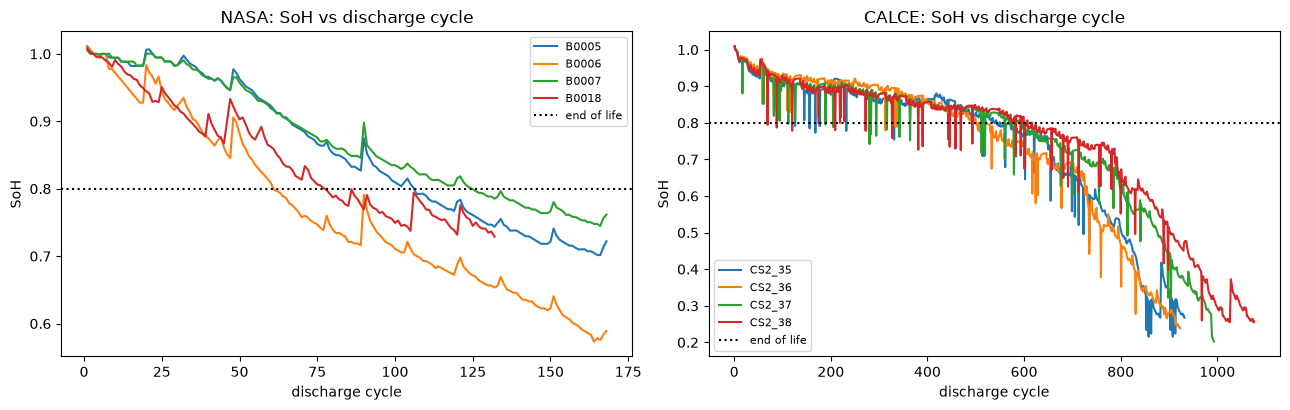

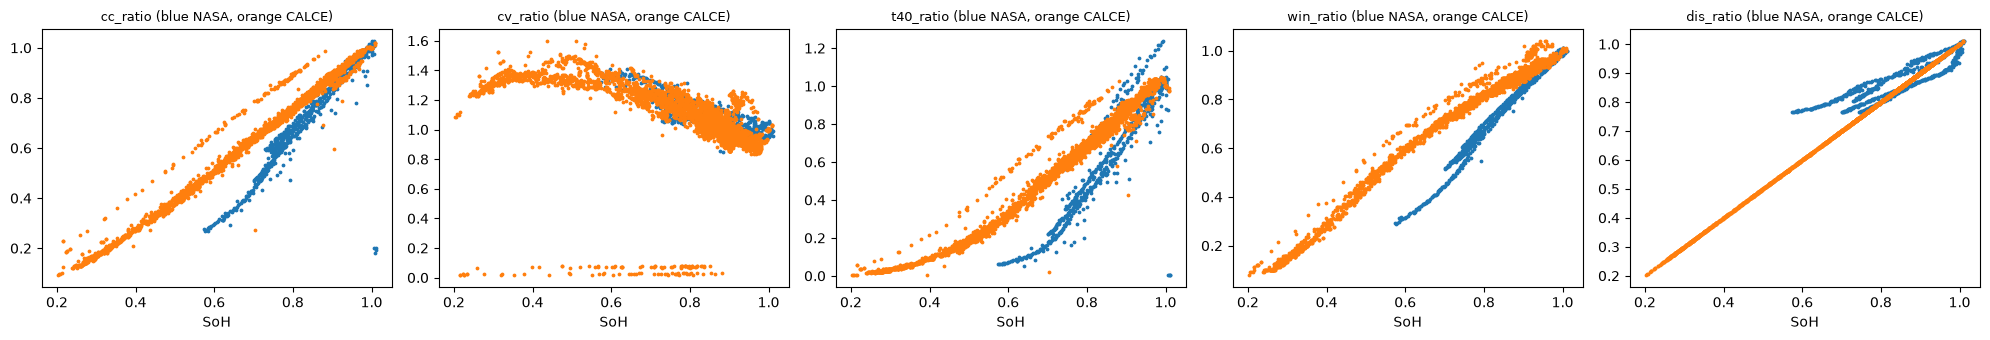

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for b, g in df.groupby('battery'):
    axes[0 if ds_of[b] == 'NASA' else 1].plot(g['cycle_no'], g['soh'], label=b)
for ax, title in zip(axes, ['NASA', 'CALCE']):
    ax.axhline(eol, color='k', ls=':', label='end of life')
    ax.set_title(title + ': SoH vs discharge cycle')
    ax.set_xlabel('discharge cycle')
    ax.set_ylabel('SoH')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'soh_curves_nasa_calce.png'), dpi=150)
plt.show()

feat_plot = ['cc_ratio', 'cv_ratio', 't40_ratio', 'win_ratio', 'dis_ratio']
fig, axes = plt.subplots(1, len(feat_plot), figsize=(4 * len(feat_plot), 3.5))
for ax, f in zip(axes, feat_plot):
    for b, g in df.groupby('battery'):
        ax.scatter(g['soh'], g[f], s=3, color='tab:blue' if ds_of[b] == 'NASA' else 'tab:orange')
    ax.set_xlabel('SoH')
    ax.set_title(f + ' (blue NASA, orange CALCE)', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'feature_vs_soh_nasa_calce.png'), dpi=150)
plt.show()
# where the blue and orange clouds follow different curves, the feature does not transfer between datasets

## 4. Experimental setup
All arms use the same feature sets, models and selection rule: an inner leave-one-battery-out grid search on the training batteries only, with the scaler fitted inside each training fold. Two baselines are included: the training mean, and Ridge regression on the cycle number alone.

Targets are `soh` and `rul_frac`. Remaining life is judged as a fraction because lifetimes differ between datasets; errors in cycles are converted back with each battery's own end-of-life cycle. The Gaussian Process cannot use sample weights and is slow, so it trains on a subsample with equal rows per training battery.

In [8]:
feats = {
    'partial': ['cc_ratio', 'cv_ratio', 't40_ratio', 'win_ratio'],
    'full': ['cc_ratio', 'cv_ratio', 't40_ratio', 'win_ratio', 'dis_ratio'],
    'cycle': ['cycle_no'],
}
jobs = [(m + '-' + fs, m, fs) for m in models for fs in ['partial', 'full']]
jobs += [('Baseline-mean', 'Dummy', 'partial'), ('Baseline-cycle-Ridge', 'Ridge', 'cycle')]


def make_model(model):
    grid = None
    if model == 'Ridge':
        est, grid = Ridge(), {'est__alpha': [0.01, 0.1, 1.0, 10.0]}
    elif model == 'RF':
        est = RandomForestRegressor(n_estimators=150, random_state=seed, n_jobs=1)
        grid = {'est__max_depth': [6, None], 'est__min_samples_leaf': [3]}
    elif model == 'GB':
        est = HistGradientBoostingRegressor(random_state=seed)
        grid = {'est__learning_rate': [0.05, 0.1], 'est__max_iter': [200], 'est__max_depth': [3]}
    elif model == 'SVR':
        est = SVR(kernel='rbf')
        grid = {'est__C': [1.0, 10.0, 100.0], 'est__epsilon': [0.02]}
    elif model == 'GPR':
        kern = ck(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=0.01)
        est = GaussianProcessRegressor(kernel=kern, normalize_y=True, n_restarts_optimizer=1, random_state=seed)
    else:
        est = DummyRegressor(strategy='mean')
    return Pipeline([('sc', StandardScaler()), ('est', est)]), grid


def subsample(g, cap):
    # equal number of evenly spaced rows from each training battery
    ids = np.unique(g)
    per = max(1, cap // len(ids))
    out = []
    for b in ids:
        ix = np.where(g == b)[0]
        if len(ix) > per:
            ix = ix[np.unique(np.linspace(0, len(ix) - 1, per).astype(int))]
        out.append(ix)
    return np.concatenate(out)


def fit_model(model, x, y, g, w):
    # returns a predict function (mean, std or None) and the chosen parameters
    pipe, grid = make_model(model)
    if model == 'GPR':
        ix = subsample(g, gpr_rows)
        pipe.fit(x[ix], y[ix])
        return (lambda z: pipe.predict(z, return_std=True)), str(pipe.named_steps['est'].kernel_)
    kw = {} if w is None else {'est__sample_weight': w}
    if grid:
        gs = GridSearchCV(pipe, grid, cv=LeaveOneGroupOut(), scoring='neg_root_mean_squared_error', n_jobs=-1)
        gs.fit(x, y, groups=g, **kw)
        best = gs.best_estimator_
        return (lambda z: (best.predict(z), None)), str(gs.best_params_)
    pipe.fit(x, y, **kw)
    return (lambda z: (pipe.predict(z), None)), ''


def train_ids(arm, held, batteries):
    others = [b for b in batteries if b != held]
    if arm == 'A':
        return [b for b in others if ds_of[b] == 'NASA']
    if arm == 'B':
        return [b for b in others if ds_of[b] == 'CALCE'] if ds_of[held] == 'CALCE' else []
    return others                      # pooled arms: C, D, D1, D2


def eol_err(cycles, pred, true_eol):
    # predicted minus true end-of-life cycle, from the first crossing of the smoothed predicted SoH
    smooth = pd.Series(pred).rolling(5, min_periods=1).median().values
    hit = np.where(smooth <= eol)[0]
    return float(cycles[hit[0]] - true_eol) if len(hit) else np.nan


rows, preds = [], {}


def run_job(label, model, fset, target, arm):
    # arms D1 and D2 are ablations of D: indicator only, and weights only
    flag = arm in ('D', 'D1')
    weighted = arm in ('D', 'D2')
    cols = feats[fset] + (['is_calce'] if flag else [])
    d = df if target == 'soh' else df[df['rul_frac'].notna()]
    batteries = sorted(d['battery'].unique())
    plan = {}
    for held in batteries:
        train = train_ids(arm, held, batteries)
        if len(train) >= 2:
            plan.setdefault(tuple(train), []).append(held)
    for train, held_list in plan.items():
        dtr = d[d['battery'].isin(train)]
        x, y, g = dtr[cols].values, dtr[target].values, dtr['battery'].values
        w = None
        if weighted:                   # each training battery carries equal total weight
            w = 1.0 / dtr['battery'].map(dtr['battery'].value_counts()).values.astype(float)
            w = w / w.mean()
        predict, params = fit_model(model, x, y, g, w)
        for h in held_list:
            te = d[d['battery'] == h]
            mu, sd = predict(te[cols].values)
            yt = te[target].values
            row = {'target': target, 'arm': arm, 'label': label, 'model': model, 'fset': fset,
                   'heldout': h, 'dataset': ds_of[h], 'n_test': len(te), 'n_train': len(dtr),
                   'train_batteries': '+'.join(train),
                   'rmse': float(np.sqrt(mean_squared_error(yt, mu))),
                   'mae': float(mean_absolute_error(yt, mu)), 'r2': float(r2_score(yt, mu)),
                   'params': params}
            if target == 'soh':
                row['eol_err_cycles'] = eol_err(te['cycle_no'].values, mu, te['eol_cycle'].iloc[0])
            else:
                row['rul_mae_cycles'] = float(np.mean(np.abs(mu - yt)) * te['eol_cycle'].iloc[0])
            if sd is not None:
                row['cov95'] = float(np.mean(np.abs(yt - mu) <= 1.96 * sd))
            rows.append(row)
            preds[(arm, h, label, target)] = (te['cycle_no'].values, yt, mu)


print('setup done; jobs:', len(jobs))

setup done; jobs: 12


## 5. Experiments
Every job is run for both targets under arms A to D.

In [9]:
for target in ['soh', 'rul_frac']:
    for arm in ['A', 'B', 'C', 'D']:
        for job in jobs:
            run_job(*job, target, arm)
        print(target, 'arm', arm, 'done')
res = pd.DataFrame(rows)
res.to_csv(os.path.join(out_dir, 'results_all.csv'), index=False)
print('result rows:', len(res), '| saved results_all.csv')

soh arm A done
soh arm B done
soh arm C done
soh arm D done
rul_frac arm A done
rul_frac arm B done
rul_frac arm C done
rul_frac arm D done
result rows: 672 | saved results_all.csv


## 6. Comparison of training arms
`C_minus_A` below zero means pooled training gave a lower error than NASA-only training on that held-out battery. With four batteries per dataset, only the direction and consistency of the differences are interpreted.

In [10]:
wide = res.pivot_table(index=['target', 'label', 'dataset', 'heldout'], columns='arm', values='rmse').reset_index()
wide['C_minus_A'] = wide['C'] - wide['A']
wide['D_minus_C'] = wide['D'] - wide['C']
summary = (wide.groupby(['target', 'dataset', 'label'])
           .agg(A=('A', 'mean'), B=('B', 'mean'), C=('C', 'mean'), D=('D', 'mean'),
                C_minus_A=('C_minus_A', 'mean'),
                C_better_count=('C_minus_A', lambda s: int((s < 0).sum())),
                n_batteries=('C_minus_A', 'count')).reset_index())
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
print('SoH: mean RMSE by arm, per held-out dataset (lower is better)')
print(summary[summary['target'] == 'soh'].round(4).to_string(index=False))
print()
print('RUL fraction: mean RMSE by arm')
print(summary[summary['target'] == 'rul_frac'].round(4).to_string(index=False))

SoH: mean RMSE by arm, per held-out dataset (lower is better)
target dataset                label      A      B      C      D  C_minus_A  C_better_count  n_batteries
   soh   CALCE Baseline-cycle-Ridge 0.8628 0.0880 0.0945 0.0894    -0.7683               4            4
   soh   CALCE        Baseline-mean 0.2101 0.1923 0.1928 0.1983    -0.0172               4            4
   soh   CALCE              GB-full 0.1147 0.0025 0.0064 0.0064    -0.1083               4            4
   soh   CALCE           GB-partial 0.1256 0.0093 0.0177 0.0111    -0.1079               4            4
   soh   CALCE             GPR-full 0.2015 0.0001 0.0108 0.0071    -0.1907               4            4
   soh   CALCE          GPR-partial 0.1473 0.0073 0.0188 0.0072    -0.1285               4            4
   soh   CALCE              RF-full 0.1177 0.0011 0.0051 0.0053    -0.1126               4            4
   soh   CALCE           RF-partial 0.1225 0.0107 0.0155 0.0128    -0.1070               4            4
  

In [11]:
eol_of = df.groupby('battery')['eol_cycle'].first().to_dict()
stages = [(0, 0.5, '1 first half of life'), (0.5, 1.0, '2 second half of life'), (1.0, np.inf, '3 after end of life')]
stage_rows = []
for (arm, held, label, target), (cyc, y, mu) in preds.items():
    if target != 'soh' or arm not in ('A', 'C', 'D'):
        continue
    frac = cyc / eol_of[held]
    for lo, hi, name in stages:
        m = (frac > lo) & (frac <= hi)
        if m.sum() > 5:
            stage_rows.append({'dataset': ds_of[held], 'label': label, 'arm': arm, 'stage': name,
                               'rmse': float(np.sqrt(np.mean((y[m] - mu[m]) ** 2)))})
tab = pd.DataFrame(stage_rows).groupby(['dataset', 'label', 'stage', 'arm'])['rmse'].mean().unstack('arm')
tab = tab[tab.index.get_level_values('label').str.contains('partial')]   # partial features only
print('SoH RMSE by life stage (mean over held-out batteries)')
print(tab.round(4).to_string())

SoH RMSE by life stage (mean over held-out batteries)
arm                                               A       C       D
dataset label         stage                                        
CALCE   GB-partial    1 first half of life   0.0390  0.0137  0.0097
                      2 second half of life  0.0615  0.0086  0.0069
                      3 after end of life    0.1818  0.0230  0.0135
        GPR-partial   1 first half of life   0.0383  0.0080  0.0064
                      2 second half of life  0.0597  0.0056  0.0037
                      3 after end of life    0.2154  0.0272  0.0091
        RF-partial    1 first half of life   0.0379  0.0104  0.0144
                      2 second half of life  0.0607  0.0067  0.0065
                      3 after end of life    0.1770  0.0212  0.0138
        Ridge-partial 1 first half of life   0.0337  0.0129  0.0426
                      2 second half of life  0.0634  0.0124  0.0203
                      3 after end of life    0.1606  0.0306  0

In [12]:
start = len(rows)
for m in models:
    for arm in ['D1', 'D2']:
        run_job(m + '-partial', m, 'partial', 'soh', arm)
    print(m, 'done')
abl = pd.DataFrame(rows[start:])
base = res[(res['target'] == 'soh') & (res['fset'] == 'partial') & res['model'].isin(models) & res['arm'].isin(['A', 'C', 'D'])]
both = pd.concat([base[['arm', 'label', 'heldout', 'dataset', 'rmse']], abl[['arm', 'label', 'heldout', 'dataset', 'rmse']]])
tab2 = both.pivot_table(index=['dataset', 'label'], columns='arm', values='rmse')[['A', 'C', 'D1', 'D2', 'D']]
print('SoH RMSE, partial features. A = NASA only, C = pooled, D1 = pooled + indicator only, D2 = pooled + weights only, D = both')
print(tab2.round(4).to_string())

Ridge done
RF done
GB done
SVR done
GPR done
SoH RMSE, partial features. A = NASA only, C = pooled, D1 = pooled + indicator only, D2 = pooled + weights only, D = both
arm                         A       C      D1      D2       D
dataset label                                                
CALCE   GB-partial     0.1256  0.0177  0.0104  0.0252  0.0111
        GPR-partial    0.1473  0.0188  0.0072  0.0188  0.0072
        RF-partial     0.1225  0.0155  0.0100  0.0212  0.0128
        Ridge-partial  0.1124  0.0223  0.0185  0.0556  0.0356
        SVR-partial    0.1484  0.0125  0.0095  0.0154  0.0101
NASA    GB-partial     0.0232  0.0635  0.0306  0.0575  0.0233
        GPR-partial    0.0536  0.0538  0.0322  0.0538  0.0322
        RF-partial     0.0222  0.0653  0.0394  0.0600  0.0439
        Ridge-partial  0.0214  0.0934  0.0628  0.0735  0.0393
        SVR-partial    0.0389  0.0613  0.0196  0.0557  0.0208


In [13]:
eol_tab = (res[(res['target'] == 'soh') & res['arm'].isin(['A', 'C'])]
           .pivot_table(index=['label', 'dataset', 'heldout'], columns='arm', values='eol_err_cycles').reset_index())
print('End-of-life crossing error in cycles from the SoH model (predicted minus true; blank = no crossing predicted)')
print(eol_tab.round(1).to_string(index=False))
print()
print('Gaussian Process 95 percent interval coverage (ideal is about 0.95)')
print(res[res['cov95'].notna()][['target', 'arm', 'fset', 'heldout', 'cov95']].round(3).to_string(index=False))

End-of-life crossing error in cycles from the SoH model (predicted minus true; blank = no crossing predicted)
               label dataset heldout      A      C
Baseline-cycle-Ridge   CALCE  CS2_35 -445.0 -188.0
Baseline-cycle-Ridge   CALCE  CS2_36 -402.0 -145.0
Baseline-cycle-Ridge   CALCE  CS2_37 -477.0 -230.0
Baseline-cycle-Ridge   CALCE  CS2_38 -501.0 -258.0
Baseline-cycle-Ridge    NASA   B0005  -13.0    NaN
Baseline-cycle-Ridge    NASA   B0006   52.0    NaN
Baseline-cycle-Ridge    NASA   B0007  -35.0    NaN
Baseline-cycle-Ridge    NASA   B0018   23.0    NaN
       Baseline-mean   CALCE  CS2_35    NaN -545.0
       Baseline-mean   CALCE  CS2_36    NaN -502.0
       Baseline-mean   CALCE  CS2_37    NaN -577.0
       Baseline-mean   CALCE  CS2_38    NaN -601.0
       Baseline-mean    NASA   B0005    NaN -108.0
       Baseline-mean    NASA   B0006    NaN  -62.0
       Baseline-mean    NASA   B0007    NaN -126.0
       Baseline-mean    NASA   B0018    NaN  -79.0
             GB-full   

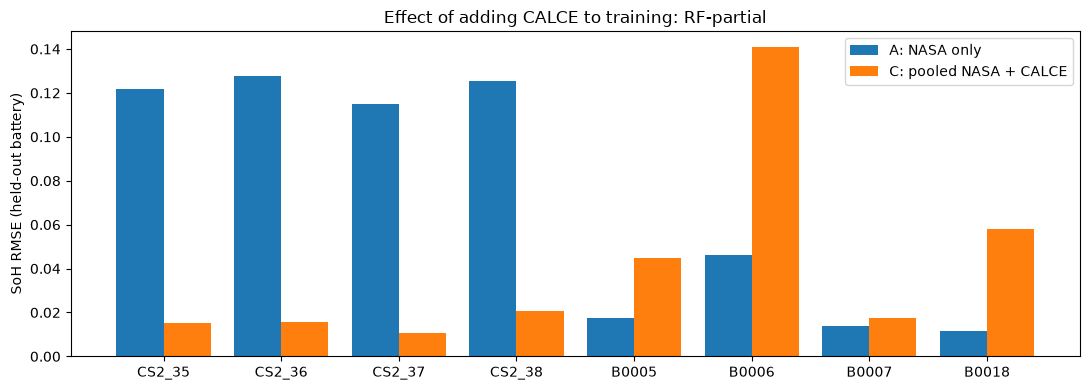

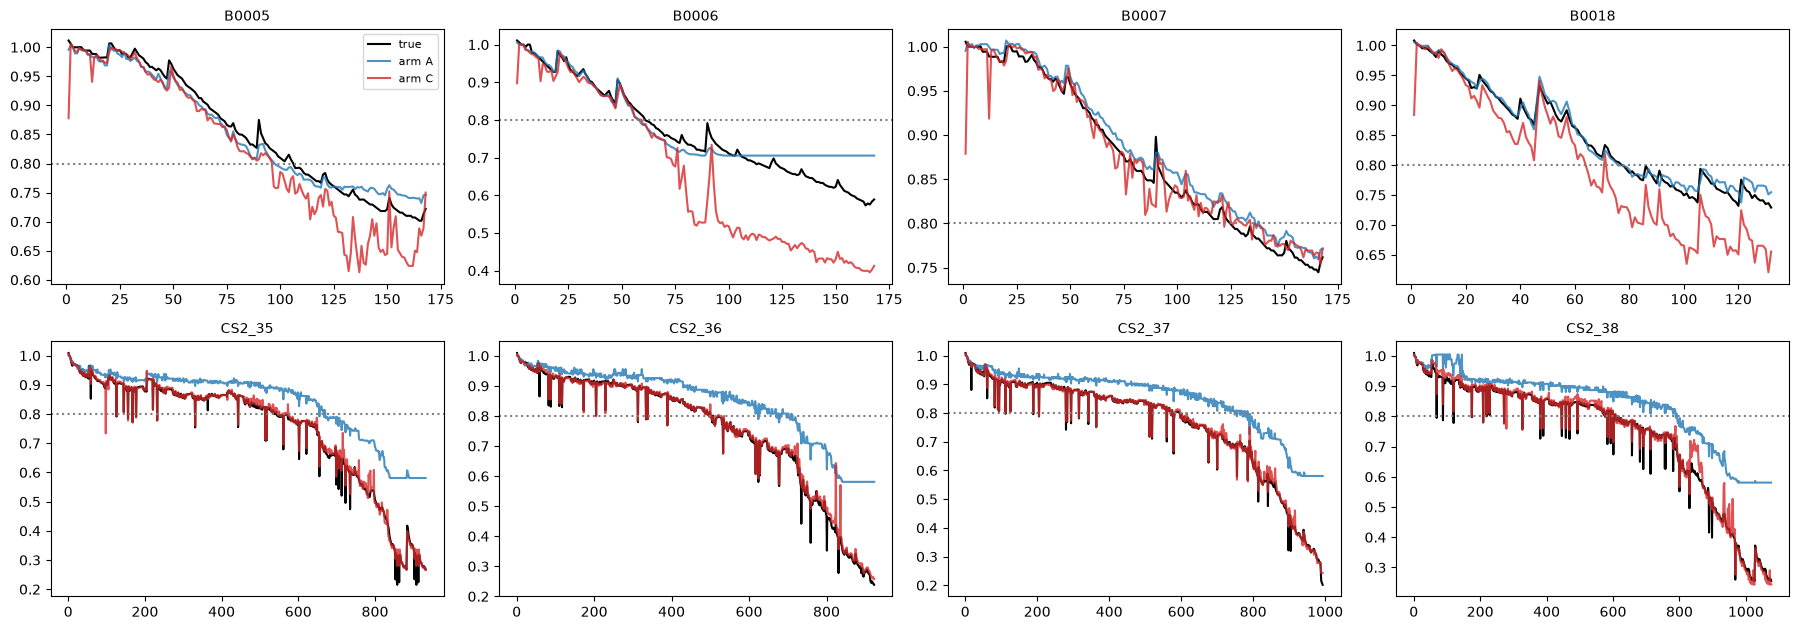

In [14]:
plot_label = 'RF-partial'          # any label from jobs, e.g. 'GB-partial', 'GPR-full'
fig, ax = plt.subplots(figsize=(11, 4))
sub = wide[(wide['target'] == 'soh') & (wide['label'] == plot_label)].sort_values(['dataset', 'heldout'])
x = np.arange(len(sub))
ax.bar(x - 0.2, sub['A'], width=0.4, label='A: NASA only')
ax.bar(x + 0.2, sub['C'], width=0.4, label='C: pooled NASA + CALCE')
ax.set_xticks(x)
ax.set_xticklabels(sub['heldout'])
ax.set_ylabel('SoH RMSE (held-out battery)')
ax.set_title('Effect of adding CALCE to training: ' + plot_label)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'compare_A_vs_C.png'), dpi=150)
plt.show()

batteries = sorted(df['battery'].unique())
ncol = 4
nrow = int(np.ceil(len(batteries) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.5 * ncol, 3.2 * nrow), squeeze=False)
for ax, b in zip(axes.ravel(), batteries):
    d = df[df['battery'] == b]
    ax.plot(d['cycle_no'], d['soh'], 'k', label='true')
    for arm, col in [('A', 'tab:blue'), ('C', 'tab:red')]:
        key = (arm, b, plot_label, 'soh')
        if key in preds:
            cyc, _, pred = preds[key]
            ax.plot(cyc, pred, color=col, alpha=0.8, label='arm ' + arm)
    ax.axhline(eol, color='gray', ls=':')
    ax.set_title(b, fontsize=10)
axes.ravel()[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'predictions_A_vs_C.png'), dpi=150)
plt.show()

## 7. Saved results
The next cell writes the summary tables to `data/processed/` and prints them in one block.

In [15]:
wide.to_csv(os.path.join(out_dir, 'results_wide_rmse.csv'), index=False)
summary.to_csv(os.path.join(out_dir, 'results_summary.csv'), index=False)
print('settings: n_early=%s eol=%s models=%s' % (n_early, eol, models))
print('--- data check ---')
print(checks.to_csv(index=False))
print('--- summary (mean RMSE by arm) ---')
print(summary.round(4).to_csv(index=False))
print('--- per-battery SoH RMSE by arm ---')
print(wide[wide['target'] == 'soh'].round(4).to_csv(index=False))
print('--- per-battery RUL-fraction RMSE by arm ---')
print(wide[wide['target'] == 'rul_frac'].round(4).to_csv(index=False))
print('--- GPR coverage ---')
print(res[res['cov95'].notna()][['target', 'arm', 'fset', 'heldout', 'cov95']].round(3).to_csv(index=False))

settings: n_early=5 eol=0.8 models=['Ridge', 'RF', 'GB', 'SVR', 'GPR']
--- data check ---
battery,dataset,cycles_loaded,dropped_missing_or_nonpositive,dropped_outliers,cycles_kept,early_capacity_Ah,final_SoH,min_SoH,eol_cycle
B0005,NASA,168,1,0,167,1.8353,0.722,0.701,109.0
B0006,NASA,168,1,0,167,2.0133,0.589,0.573,63.0
B0007,NASA,168,1,0,167,1.8807,0.762,0.745,127.0
B0018,NASA,132,2,0,130,1.8396,0.729,0.729,80.0
CS2_35,CALCE,932,5,1,926,1.1283,0.267,0.215,546.0
CS2_36,CALCE,973,56,2,915,1.134,0.238,0.238,503.0
CS2_37,CALCE,1037,49,1,987,1.1245,0.202,0.202,578.0
CS2_38,CALCE,1076,8,2,1066,1.1286,0.255,0.255,602.0

--- summary (mean RMSE by arm) ---
target,dataset,label,A,B,C,D,C_minus_A,C_better_count,n_batteries
rul_frac,CALCE,Baseline-cycle-Ridge,2.0374,0.0448,0.101,0.066,-1.9363,4,4
rul_frac,CALCE,Baseline-mean,0.289,0.289,0.289,0.289,-0.0,4,4
rul_frac,CALCE,GB-full,0.1918,0.1343,0.1269,0.1284,-0.0649,4,4
rul_frac,CALCE,GB-partial,0.2034,0.135,0.1249,0.1202,-0.0785,4,4
rul_frac,CALCE

## 8. Final model
The final model is an RBF support vector regressor on the `partial` features plus the dataset indicator, trained on all batteries without sample weights (arm D1). It was chosen on the leave-one-battery-out results above for four reasons:
- Among the pooled models with the indicator, it has the lowest NASA error (0.0196) and an error on CALCE (0.0095) close to the best model on that dataset.
- It avoids the near-leaking discharge-time feature.
- It is deterministic, so its results do not depend on a random seed.
- A single pipeline serves both datasets.

The Gaussian Process has a lower CALCE error but a higher NASA error and overconfident built-in intervals. The tree models are no better on either dataset. Selecting among five candidates on the same validation scheme is mildly optimistic, which the report should state.

In [16]:
cand = abl[abl['arm'] == 'D1'].groupby(['label', 'dataset'])['rmse'].mean().unstack('dataset')
print('SoH RMSE, partial features, pooled with indicator (D1), mean over held-out batteries')
print(cand.round(4).to_string())

SoH RMSE, partial features, pooled with indicator (D1), mean over held-out batteries
dataset         CALCE    NASA
label                        
GB-partial     0.0104  0.0306
GPR-partial    0.0072  0.0322
RF-partial     0.0100  0.0394
Ridge-partial  0.0185  0.0628
SVR-partial    0.0095  0.0196


In [17]:
final_cols = feats['partial'] + ['is_calce']
batteries = sorted(df['battery'].unique())
x_all, y_all, g_all = df[final_cols].values, df['soh'].values, df['battery'].values


def svr_fit(x, y, c):
    pipe = Pipeline([('sc', StandardScaler()), ('est', SVR(kernel='rbf', C=c, epsilon=0.02))])
    return pipe.fit(x, y)


def rmse_of(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))


# regularisation strength chosen by leave-one-battery-out over all batteries
scores = {}
for c in [1.0, 10.0, 100.0]:
    scores[c] = np.mean([rmse_of(y_all[g_all == b], svr_fit(x_all[g_all != b], y_all[g_all != b], c).predict(x_all[g_all == b]))
                         for b in batteries])
best_c = min(scores, key=scores.get)
print('mean RMSE by C:', {k: round(v, 4) for k, v in scores.items()}, '| chosen C =', best_c)

# calibrated 95 percent intervals. For held-out battery b, the residuals come from the other
# batteries of the same dataset, each predicted by a model that has not seen b or that battery.
level = 0.95
fin, cal_rows = {}, []
for b in batteries:
    rest = [k for k in batteries if k != b]
    res_same, res_all = [], []
    for o in rest:
        inner = [k for k in rest if k != o]
        m_in = np.isin(g_all, inner)
        r = np.abs(y_all[g_all == o] - svr_fit(x_all[m_in], y_all[m_in], best_c).predict(x_all[g_all == o]))
        res_all.append(r)
        if ds_of[o] == ds_of[b]:
            res_same.append(r)
    q_same = float(np.quantile(np.concatenate(res_same), level))
    q_all = float(np.quantile(np.concatenate(res_all), level))
    mb = g_all == b
    mu = svr_fit(x_all[~mb], y_all[~mb], best_c).predict(x_all[mb])
    d = df[df['battery'] == b]
    fin[b] = {'cyc': d['cycle_no'].values, 'y': y_all[mb], 'mu': mu, 'q': q_same}
    up_to_eol = d['cycle_no'].values <= d['eol_cycle'].iloc[0]
    err = np.abs(y_all[mb] - mu)
    cal_rows.append({'battery': b, 'dataset': ds_of[b], 'rmse': rmse_of(y_all[mb], mu),
                     'half_width_same_dataset': q_same, 'coverage_same_dataset': float(np.mean(err <= q_same)),
                     'coverage_to_eol': float(np.mean(err[up_to_eol] <= q_same)),
                     'half_width_all': q_all, 'coverage_all': float(np.mean(err <= q_all))})
cal = pd.DataFrame(cal_rows)
print('Calibrated 95 percent intervals, final model (nested leave-one-battery-out)')
print(cal.round(3).to_string(index=False))
print()
print(cal.groupby('dataset')[['rmse', 'half_width_same_dataset', 'coverage_same_dataset', 'coverage_to_eol', 'coverage_all']].mean().round(3).to_string())

mean RMSE by C: {1.0: np.float64(0.0145), 10.0: np.float64(0.0153), 100.0: np.float64(0.0172)} | chosen C = 1.0
Calibrated 95 percent intervals, final model (nested leave-one-battery-out)
battery dataset  rmse  half_width_same_dataset  coverage_same_dataset  coverage_to_eol  half_width_all  coverage_all
  B0005    NASA 0.016                    0.059                  1.000            1.000           0.020         0.760
  B0006    NASA 0.027                    0.031                  0.826            1.000           0.021         0.623
  B0007    NASA 0.019                    0.045                  1.000            1.000           0.020         0.533
  B0018    NASA 0.016                    0.040                  1.000            1.000           0.022         0.800
 CS2_35   CALCE 0.010                    0.021                  0.968            0.989           0.025         0.974
 CS2_36   CALCE 0.010                    0.017                  0.890            0.972           0.024        

In [18]:
def true_eol(b, thr):
    d = df[df['battery'] == b]
    hit = np.where(d['soh'].rolling(5, min_periods=1).median().values <= thr)[0]
    return float(d['cycle_no'].iloc[hit[0]]) if len(hit) else np.nan


def forecast_eol(cyc, soh, t, level_soh, frac=0.4):
    # straight line through the smoothed SoH of the last 40 percent of the cycles up to t,
    # extrapolated to level_soh; only information up to cycle t is used
    keep = cyc <= t
    c = cyc[keep]
    s = pd.Series(soh[keep]).rolling(5, min_periods=1).median().values
    n = max(10, int(frac * len(c)))
    slope, icpt = np.polyfit(c[-n:], s[-n:], 1)
    return np.nan if slope >= 0 else float((level_soh - icpt) / slope)


def forecast_table(thr, points=(0.25, 0.5, 0.75)):
    life = {b: true_eol(b, thr) for b in batteries}
    out = []
    for b in batteries:
        if np.isnan(life[b]):
            continue
        f = fin[b]
        mates = [life[o] for o in batteries if o != b and ds_of[o] == ds_of[b] and not np.isnan(life[o])]
        for p in points:
            t = f['cyc'][f['cyc'] <= p * life[b]].max()
            mid = forecast_eol(f['cyc'], f['mu'], t, thr)
            early = forecast_eol(f['cyc'], f['mu'], t, thr + f['q'])
            late = forecast_eol(f['cyc'], f['mu'], t, thr - f['q'])
            orc = forecast_eol(f['cyc'], f['y'], t, thr)
            base = float(np.mean(mates)) if mates else np.nan
            out.append({'battery': b, 'dataset': ds_of[b], 'point': p, 'true_eol': life[b], 'forecast_eol': mid,
                        'band_low': early, 'band_high': late,
                        'model_err': abs(mid - life[b]) / life[b], 'oracle_err': abs(orc - life[b]) / life[b],
                        'base_err': abs(base - life[b]) / life[b],
                        'covered': bool(early <= life[b] <= late)})
    return pd.DataFrame(out)


ft = forecast_table(eol)
print('End-of-life forecast at 25, 50 and 75 percent of life (error as a fraction of true life)')
print(ft.round(3).to_string(index=False))
print()
print(ft.groupby(['dataset', 'point'])[['model_err', 'oracle_err', 'base_err', 'covered']].mean().round(3).to_string())

End-of-life forecast at 25, 50 and 75 percent of life (error as a fraction of true life)
battery dataset  point  true_eol  forecast_eol  band_low  band_high  model_err  oracle_err  base_err  covered
  B0005    NASA   0.25     109.0           NaN       NaN        NaN        NaN         NaN     0.174    False
  B0005    NASA   0.50     109.0       160.534   117.344    203.725      0.473       0.352     0.174    False
  B0005    NASA   0.75     109.0        95.646    78.906    112.387      0.123       0.116     0.174     True
  B0006    NASA   0.25      63.0        77.498    65.756     89.241      0.230       0.313     0.672    False
  B0006    NASA   0.50      63.0       174.438   144.494    204.381      1.769       1.588     0.672    False
  B0006    NASA   0.75      63.0        58.660    52.446     64.874      0.069       0.031     0.672     True
  B0007    NASA   0.25     127.0           NaN       NaN        NaN        NaN         NaN     0.339    False
  B0007    NASA   0.50     127.

In [19]:
# threshold sensitivity (SoH predictions do not depend on the threshold)
sens = []
for thr in [0.70, 0.75, 0.80, 0.85]:
    t = forecast_table(thr)
    det = []
    for b in batteries:
        life = true_eol(b, thr)
        if np.isnan(life):
            continue
        sm = pd.Series(fin[b]['mu']).rolling(5, min_periods=1).median().values
        hit = np.where(sm <= thr)[0]
        det.append(abs(fin[b]['cyc'][hit[0]] - life) / life if len(hit) else np.nan)
    half = t[t['point'] == 0.5]
    sens.append({'threshold': thr, 'batteries_crossing': t['battery'].nunique(),
                 'detection_err': np.nanmean(det) if det else np.nan,
                 'forecast_err_50pct': half['model_err'].mean(), 'baseline_err_50pct': half['base_err'].mean(),
                 'band_coverage_50pct': half['covered'].mean()})
print('Sensitivity to the end-of-life threshold (errors as a fraction of true life)')
print(pd.DataFrame(sens).round(3).to_string(index=False))

# seed sensitivity of the seed-dependent candidates, pooled with indicator (D1)
seed_rows = []
for s in [0, 1, 2]:
    seed = s
    for m in ['RF', 'GB']:
        n0 = len(rows)
        run_job('%s-s%d' % (m, s), m, 'partial', 'soh', 'D1')
        for r in rows[n0:]:
            r['seed'] = s
            seed_rows.append(r)
seed = 0
sd = pd.DataFrame(seed_rows).groupby(['model', 'dataset', 'seed'])['rmse'].mean().unstack('seed')
sd['spread'] = sd.max(axis=1) - sd.min(axis=1)
print()
print('SoH RMSE of the seed-dependent candidates across seeds')
print(sd.round(4).to_string())
print('final SVR (deterministic):', cal.groupby('dataset')['rmse'].mean().round(4).to_dict())

Sensitivity to the end-of-life threshold (errors as a fraction of true life)
 threshold  batteries_crossing  detection_err  forecast_err_50pct  baseline_err_50pct  band_coverage_50pct
      0.70                   5          0.044               0.412               0.100                0.200
      0.75                   8          0.039               0.402               0.223                0.250
      0.80                   8          0.029               4.446               0.219                0.125
      0.85                   8          0.045               0.542               0.158                0.125

SoH RMSE of the seed-dependent candidates across seeds
seed                0       1       2  spread
model dataset                                
GB    CALCE    0.0104  0.0104  0.0104  0.0000
      NASA     0.0306  0.0306  0.0306  0.0000
RF    CALCE    0.0100  0.0099  0.0100  0.0001
      NASA     0.0394  0.0372  0.0366  0.0028
final SVR (deterministic): {'CALCE': 0.0095, 'NASA': 0.0

Permutation importance (RMSE increase, mean over held-out batteries of each dataset)
dataset     CALCE    NASA
feature                  
cc_ratio   0.1045  0.0283
cv_ratio   0.0264  0.0042
is_calce   0.1062  0.0811
t40_ratio  0.0649  0.0263
win_ratio  0.1618  0.1007


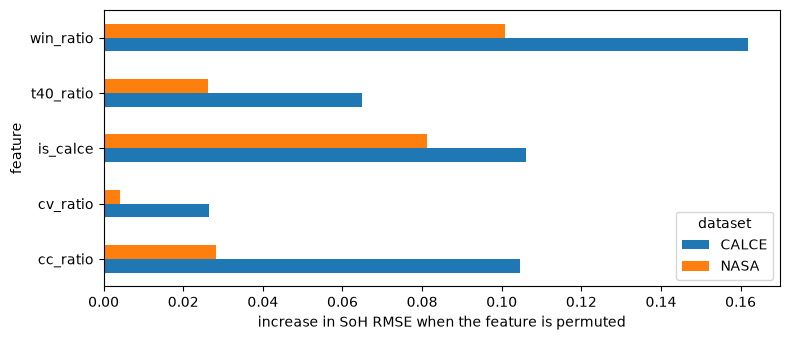

In [20]:
# permutation importance: increase in held-out RMSE when one feature is shuffled (indicator: flipped)
rng = np.random.default_rng(seed)
imp = []
for b in batteries:
    m_b = g_all == b
    model = svr_fit(x_all[~m_b], y_all[~m_b], best_c)
    xb, yb = x_all[m_b], y_all[m_b]
    base_err = rmse_of(yb, model.predict(xb))
    for j, name in enumerate(final_cols):
        inc = []
        for _ in range(20):
            xp = xb.copy()
            xp[:, j] = 1 - xp[:, j] if name == 'is_calce' else rng.permutation(xp[:, j])
            inc.append(rmse_of(yb, model.predict(xp)) - base_err)
        imp.append({'battery': b, 'dataset': ds_of[b], 'feature': name, 'rmse_increase': float(np.mean(inc))})
imp = pd.DataFrame(imp)
imp_tab = imp.groupby(['dataset', 'feature'])['rmse_increase'].mean().unstack('dataset')
print('Permutation importance (RMSE increase, mean over held-out batteries of each dataset)')
print(imp_tab.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
imp_tab.plot.barh(ax=ax)
ax.set_xlabel('increase in SoH RMSE when the feature is permuted')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'permutation_importance.png'), dpi=150)
plt.show()

In [22]:
import json, joblib, sklearn

model_dir = os.path.join(root, 'models')
os.makedirs(model_dir, exist_ok=True)
final = svr_fit(x_all, y_all, best_c)
joblib.dump(final, os.path.join(model_dir, 'final_pipeline.joblib'))

# deployed half-widths: 95th percentile of the leave-one-battery-out absolute errors per dataset
half = cal.groupby('dataset')['half_width_same_dataset'].mean().round(4).to_dict()
card = {
    'version': '1.0',
    'model': 'SVR (RBF), C=%s, epsilon=0.02, standardised inputs' % best_c,
    'features': final_cols,
    'is_calce': '1 for CALCE-type cells, 0 for NASA-type cells',
    'feature_definitions': {'cc_ratio': 'time to first reach %.2f V during charge / early-life median' % v_cc,
                            'cv_ratio': 'time from %.2f V to end of charge / early-life median' % v_cc,
                            't40_ratio': 'time to reach %.1f V during charge / early-life median' % v_mid,
                            'win_ratio': 'capacity discharged between %.1f V and %.1f V / early-life median' % (v_hi, v_lo)},
    'early_life_cycles': n_early,
    'end_of_life_soh': eol,
    'interval_level': level,
    'interval_half_width_soh': half,
    'loo_rmse_by_dataset': cal.groupby('dataset')['rmse'].mean().round(4).to_dict(),
    'nested_coverage_by_dataset': cal.groupby('dataset')['coverage_same_dataset'].mean().round(3).to_dict(),
    'training_batteries': batteries,
    'sklearn_version': sklearn.__version__,
}
with open(os.path.join(model_dir, 'model_card.json'), 'w') as fh:
    json.dump(card, fh, indent=2)

check = joblib.load(os.path.join(model_dir, 'final_pipeline.joblib')).predict(x_all[:5])
print('saved to', model_dir, '| reload check, max difference:', float(np.max(np.abs(check - final.predict(x_all[:5])))))
print(json.dumps(card, indent=2))

saved to ../models | reload check, max difference: 0.0
{
  "version": "1.0",
  "model": "SVR (RBF), C=1.0, epsilon=0.02, standardised inputs",
  "features": [
    "cc_ratio",
    "cv_ratio",
    "t40_ratio",
    "win_ratio",
    "is_calce"
  ],
  "is_calce": "1 for CALCE-type cells, 0 for NASA-type cells",
  "feature_definitions": {
    "cc_ratio": "time to first reach 4.19 V during charge / early-life median",
    "cv_ratio": "time from 4.19 V to end of charge / early-life median",
    "t40_ratio": "time to reach 4.0 V during charge / early-life median",
    "win_ratio": "capacity discharged between 3.8 V and 3.4 V / early-life median"
  },
  "early_life_cycles": 5,
  "end_of_life_soh": 0.8,
  "interval_level": 0.95,
  "interval_half_width_soh": {
    "CALCE": 0.0193,
    "NASA": 0.0439
  },
  "loo_rmse_by_dataset": {
    "CALCE": 0.0095,
    "NASA": 0.0196
  },
  "nested_coverage_by_dataset": {
    "CALCE": 0.958,
    "NASA": 0.957
  },
  "training_batteries": [
    "B0005",
    "B00